
# Componente predictivo — Cantidad de cilindros del próximo mes

### Criterios metodológicos
- El dataset `dataset_completo_cruzado.csv` se considera previamente preparado.
- `ID` se conserva solo para trazabilidad y **no se usa como predictor**.
- `Suma_total`, `n_despachos`, `meses_activos`, `intervalo_median`, `cv_intervalo` e `id_num` se excluyen de la evaluación temporal porque resumen información del año completo y pueden introducir *data leakage*.
- Los meses sin despachos se conservan como `0`.
- Cada observación usa únicamente meses anteriores al mes objetivo.
- La validación y el test respetan el orden temporal.
- La salida final permite `0` cilindros.
- La métrica principal para seleccionar el modelo es **MAE**.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import warnings

from google.colab import files
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


## 1. Cargar el dataset

In [ ]:

uploaded = files.upload()
csv_files = [n for n in uploaded.keys() if n.lower().endswith('.csv')]
if len(csv_files) != 1:
    raise ValueError('Debes subir exactamente un archivo CSV.')
name = csv_files[0]
df = pd.read_csv(name, sep=None, engine='python')
print(f'Archivo: {name}')
print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')
display(df.head())


Saving dataset_completo_cruzado.csv to dataset_completo_cruzado (1).csv
Archivo: dataset_completo_cruzado (1).csv
Filas: 1,048 | Columnas: 21


,Edad,Comunas,Sexo,ID,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,Suma_total,id_num,n_despachos,meses_activos,intervalo_median,cv_intervalo
0,85.0,SAN JAVIER,Femenino,1,0,0,0,0,0,0,0,0,0,1,0,1,1,3.0,3.0,127.5,0.249567
1,84.0,PUCON,Masculino,2,2,2,3,5,4,4,5,4,4,5,4,42,2,42.0,11.0,7.0,0.360022
2,101.0,NUNOA,Femenino,4,0,0,0,0,0,0,0,0,1,0,1,2,4,3.0,3.0,155.0,1.003635
3,92.0,VITACURA,Femenino,6,2,1,1,1,1,1,0,0,2,0,1,10,6,10.0,8.0,31.0,0.633324
4,103.0,PROVIDENCIA,Femenino,8,0,2,0,1,0,2,0,2,2,2,1,12,8,15.0,9.0,19.0,0.531362


## 2. Validación estructural

In [ ]:

df.columns = [str(c).strip() for c in df.columns]
df = df.rename(columns={
    'Edad':'edad', 'Comunas':'comuna', 'Sexo':'sexo',
    'ID':'id', 'Suma_total':'suma_total'
})

MONTHS = ['ene','feb','mar','abr','may','jun','jul','ago','sep','oct','nov']
required = ['edad','comuna','sexo','id'] + MONTHS
missing = [x for x in required if x not in df.columns]
if missing:
    raise ValueError(f'Faltan columnas: {missing}')

df['edad'] = pd.to_numeric(df['edad'], errors='coerce')
for m in MONTHS:
    df[m] = pd.to_numeric(df[m], errors='coerce')

monthly_missing = int(df[MONTHS].isna().sum().sum())
df[MONTHS] = df[MONTHS].fillna(0)

if (df[MONTHS] < 0).any().any():
    raise ValueError('Hay cantidades mensuales negativas.')

print('Validación completada')
print('Valores mensuales vacíos convertidos a 0:', monthly_missing)
print('IDs únicos:', df['id'].nunique(), '/', len(df))
print('Edades faltantes:', df['edad'].isna().sum())
print('Comunas faltantes:', df['comuna'].isna().sum())
print('Sexo faltante:', df['sexo'].isna().sum())


Validación completada
Valores mensuales vacíos convertidos a 0: 0
IDs únicos: 1048 / 1048
Edades faltantes: 0
Comunas faltantes: 0
Sexo faltante: 0



## 3. Crear el dataset supervisado

Para cada paciente se crean observaciones mensuales. Por ejemplo, para predecir julio se usan únicamente enero–junio. No se usan estadísticas calculadas con meses futuros.


In [ ]:

def recent_trend(values):
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return 0.0
    return float(np.polyfit(np.arange(len(values)), values, 1)[0])


def build_supervised_panel(data, min_lags=3):
    rows = []
    for _, row in data.iterrows():
        vals = row[MONTHS].to_numpy(dtype=float)
        for target_idx in range(min_lags, len(MONTHS)):
            hist = vals[:target_idx]
            last3 = hist[-3:]
            rows.append({
                'id': row['id'],
                'edad': row['edad'],
                'comuna': row['comuna'],
                'sexo': row['sexo'],
                'target_month_num': target_idx + 1,
                'target_month_name': MONTHS[target_idx],
                'lag_1': hist[-1],
                'lag_2': hist[-2],
                'lag_3': hist[-3],
                'hist_mean': float(np.mean(hist)),
                'hist_median': float(np.median(hist)),
                'hist_std': float(np.std(hist)),
                'hist_min': float(np.min(hist)),
                'hist_max': float(np.max(hist)),
                'hist_sum': float(np.sum(hist)),
                'hist_nonzero_rate': float(np.mean(hist > 0)),
                'recent_trend': recent_trend(last3),
                'months_observed': len(hist),
                'target': vals[target_idx]
            })
    return pd.DataFrame(rows)

panel = build_supervised_panel(df)
print(f'Instancias: {len(panel):,}')
print(f'Pacientes: {panel.id.nunique():,}')
print('Meses objetivo:', sorted(panel.target_month_num.unique()))
display(panel.head(10))


Instancias: 8,384
Pacientes: 1,048
Meses objetivo: [np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)]


,id,edad,comuna,sexo,target_month_num,target_month_name,lag_1,lag_2,lag_3,hist_mean,hist_median,hist_std,hist_min,hist_max,hist_sum,hist_nonzero_rate,recent_trend,months_observed,target
0,1,85.0,SAN JAVIER,Femenino,4,abr,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,3,0.0
1,1,85.0,SAN JAVIER,Femenino,5,may,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,4,0.0
2,1,85.0,SAN JAVIER,Femenino,6,jun,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,5,0.0
3,1,85.0,SAN JAVIER,Femenino,7,jul,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,6,0.0
4,1,85.0,SAN JAVIER,Femenino,8,ago,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,7,0.0
5,1,85.0,SAN JAVIER,Femenino,9,sep,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,8,0.0
6,1,85.0,SAN JAVIER,Femenino,10,oct,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,9,1.0
7,1,85.0,SAN JAVIER,Femenino,11,nov,1.0,0.0,0.0,0.100000,0.0,0.300000,0.0,1.0,1.0,0.1,0.5,10,0.0
8,2,84.0,PUCON,Masculino,4,abr,3.0,2.0,2.0,2.333333,2.0,0.471405,2.0,3.0,7.0,1.0,0.5,3,5.0
9,2,84.0,PUCON,Masculino,5,may,5.0,3.0,2.0,3.000000,2.5,1.224745,2.0,5.0,12.0,1.0,1.5,4,4.0


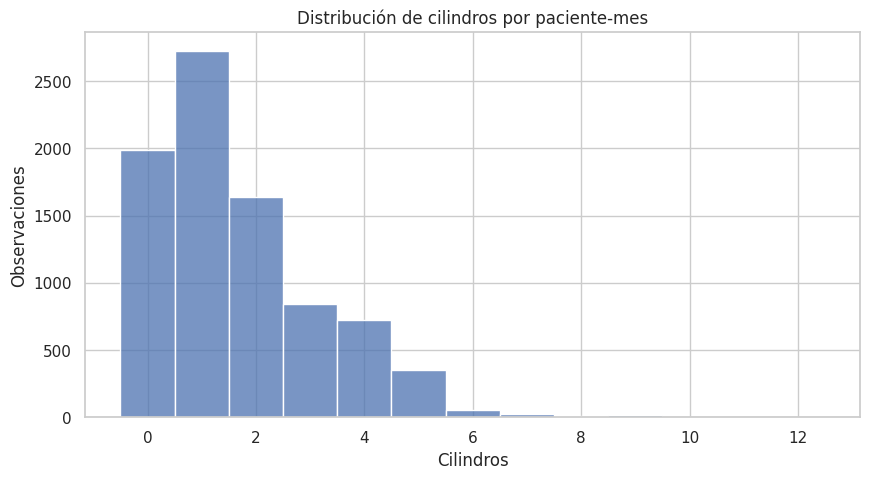

count    8384.000000
mean        1.671756
std         1.550789
min         0.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        12.000000
Name: target, dtype: float64


In [ ]:

plt.figure(figsize=(10,5))
sns.histplot(panel['target'], discrete=True)
plt.title('Distribución de cilindros por paciente-mes')
plt.xlabel('Cilindros')
plt.ylabel('Observaciones')
plt.show()
print(panel['target'].describe())



## 4. Variables del modelo

Se excluyen `id`, `id_num`, `suma_total`, `n_despachos`, `meses_activos`, `intervalo_median` y `cv_intervalo` del entrenamiento temporal. El ID se conserva solo para trazabilidad.


In [ ]:

NUMERIC_FEATURES = [
    'edad','target_month_num','lag_1','lag_2','lag_3',
    'hist_mean','hist_median','hist_std','hist_min','hist_max',
    'hist_sum','hist_nonzero_rate','recent_trend','months_observed'
]
CATEGORICAL_FEATURES = ['comuna','sexo']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES


def make_preprocessor():
    numeric_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median'))
    ])
    try:
        encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
    categorical_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', encoder)
    ])
    return ColumnTransformer([
        ('num', numeric_pipe, NUMERIC_FEATURES),
        ('cat', categorical_pipe, CATEGORICAL_FEATURES)
    ])


def make_pipeline(model):
    return Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', model)
    ])


## 5. Modelos candidatos

In [ ]:

MODELS = {
    'GradientBoosting': GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.03, max_depth=3,
        min_samples_leaf=5, loss='huber', random_state=RANDOM_STATE
    ),
    'RandomForest': RandomForestRegressor(
        n_estimators=300, max_depth=12, min_samples_leaf=3,
        max_features=0.8, random_state=RANDOM_STATE, n_jobs=-1
    )
}


## 6. Métricas

In [ ]:

def evaluate_predictions(y_true, y_pred_raw):
    y_true = np.asarray(y_true, dtype=float)
    y_pred_raw = np.asarray(y_pred_raw, dtype=float)
    y_pred_int = np.clip(np.rint(y_pred_raw), 0, None).astype(int)
    errors = y_true - y_pred_int
    metrics = {
        'MAE': mean_absolute_error(y_true, y_pred_raw),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred_raw)),
        'R2': r2_score(y_true, y_pred_raw),
        'Exactitud': np.mean(errors == 0),
        'Dentro_1': np.mean(np.abs(errors) <= 1),
        'Subestima': np.mean(errors > 0),
        'Sobreestima': np.mean(errors < 0)
    }
    return metrics, y_pred_int



## 7. Backtesting temporal

Se comparan los modelos usando julio, agosto y septiembre como meses de validación sucesivos. En cada fold solo se entrena con meses objetivo anteriores al mes validado.


In [ ]:

BACKTEST_MONTHS = [7, 8, 9]
rows = []

for model_name, model in MODELS.items():
    for month_test in BACKTEST_MONTHS:
        train_fold = panel[panel.target_month_num < month_test]
        valid_fold = panel[panel.target_month_num == month_test]
        pipe = make_pipeline(clone(model))
        pipe.fit(train_fold[FEATURES], train_fold['target'])
        pred = pipe.predict(valid_fold[FEATURES])
        metrics, _ = evaluate_predictions(valid_fold['target'], pred)
        rows.append({'Modelo':model_name, 'Mes_validacion':month_test, 'N':len(valid_fold), **metrics})

backtest = pd.DataFrame(rows)
display(backtest.round(4))


,Modelo,Mes_validacion,N,MAE,RMSE,R2,Exactitud,Dentro_1,Subestima,Sobreestima
0,GradientBoosting,7,1048,0.6853,0.9191,0.6596,0.4981,0.8941,0.3092,0.1927
1,GradientBoosting,8,1048,0.6424,0.8683,0.6756,0.5277,0.9103,0.2624,0.2099
2,GradientBoosting,9,1048,0.6302,0.8684,0.6854,0.5286,0.9342,0.2433,0.2281
3,RandomForest,7,1048,0.6781,0.9205,0.6585,0.4981,0.8941,0.2910,0.2109
4,RandomForest,8,1048,0.6446,0.8875,0.6611,0.5296,0.9122,0.2452,0.2252
5,RandomForest,9,1048,0.6319,0.8774,0.6789,0.5229,0.9275,0.2309,0.2462


In [ ]:

summary_backtest = backtest.groupby('Modelo').agg(
    MAE=('MAE','mean'), RMSE=('RMSE','mean'), R2=('R2','mean'),
    Exactitud=('Exactitud','mean'), Dentro_1=('Dentro_1','mean')
).sort_values(['MAE','Dentro_1'], ascending=[True,False])

display(summary_backtest.round(4))
BEST_MODEL_NAME = summary_backtest.index[0]
print('Modelo seleccionado:', BEST_MODEL_NAME)


,MAE,RMSE,R2,Exactitud,Dentro_1
Modelo,,,,,
RandomForest,0.6515,0.8951,0.6662,0.5169,0.9113
GradientBoosting,0.6526,0.8853,0.6735,0.5181,0.9128


Modelo seleccionado: RandomForest


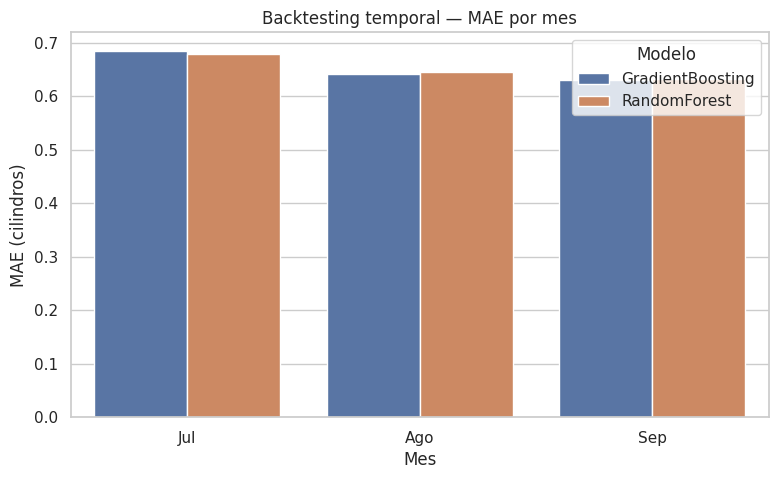

In [ ]:

plot_bt = backtest.copy()
plot_bt['Mes'] = plot_bt['Mes_validacion'].map({7:'Jul',8:'Ago',9:'Sep'})
plt.figure(figsize=(9,5))
sns.barplot(data=plot_bt, x='Mes', y='MAE', hue='Modelo')
plt.title('Backtesting temporal — MAE por mes')
plt.ylabel('MAE (cilindros)')
plt.show()



## 8. Test final — octubre y noviembre

Octubre y noviembre permanecen fuera de la selección del modelo. El modelo elegido se entrena con los targets disponibles hasta septiembre y se evalúa en esos dos meses.


In [ ]:

train_final = panel[panel.target_month_num <= 9].copy()
test_final = panel[panel.target_month_num.isin([10,11])].copy()

best_pipe = make_pipeline(clone(MODELS[BEST_MODEL_NAME]))
best_pipe.fit(train_final[FEATURES], train_final['target'])

test_pred_raw = best_pipe.predict(test_final[FEATURES])
test_metrics, test_pred_int = evaluate_predictions(test_final['target'], test_pred_raw)

print('Modelo:', BEST_MODEL_NAME)
for k,v in test_metrics.items():
    if k in ['Exactitud','Dentro_1','Subestima','Sobreestima']:
        print(f'{k:12s}: {v*100:.2f}%')
    else:
        print(f'{k:12s}: {v:.4f}')


Modelo: RandomForest
MAE         : 0.6603
RMSE        : 0.9553
R2          : 0.6586
Exactitud   : 51.05%
Dentro_1    : 91.56%
Subestima   : 25.43%
Sobreestima : 23.52%


### Comparación con baselines

In [ ]:

baseline_rows=[]
for name_b, pred in {
    'Último mes': test_final['lag_1'].values,
    'Mediana histórica': test_final['hist_median'].values
}.items():
    m,_ = evaluate_predictions(test_final['target'], pred)
    baseline_rows.append({'Modelo':name_b, **m})
baseline_rows.append({'Modelo':BEST_MODEL_NAME, **test_metrics})
comparison_test = pd.DataFrame(baseline_rows).set_index('Modelo')
display(comparison_test.round(4))


,MAE,RMSE,R2,Exactitud,Dentro_1,Subestima,Sobreestima
Modelo,,,,,,,
Último mes,0.7519,1.1116,0.5377,0.4094,0.8850,0.2901,0.3006
Mediana histórica,0.6985,1.1593,0.4972,0.4895,0.8802,0.3144,0.1961
RandomForest,0.6603,0.9553,0.6586,0.5105,0.9156,0.2543,0.2352


### Resultados individuales del test

In [ ]:

test_results = test_final[['id','target_month_num','target_month_name','target']].copy()
test_results['pred_raw'] = test_pred_raw
test_results['pred_cilindros'] = test_pred_int
test_results['error'] = test_results['target'] - test_results['pred_cilindros']
test_results['error_abs'] = np.abs(test_results['error'])
display(test_results.head(20))


,id,target_month_num,target_month_name,target,pred_raw,pred_cilindros,error,error_abs
6,1,10,oct,1.0,0.160172,0,1.0,1.0
7,1,11,nov,0.0,0.184486,0,0.0,0.0
14,2,10,oct,5.0,4.266290,4,1.0,1.0
15,2,11,nov,4.0,3.740942,4,0.0,0.0
22,4,10,oct,0.0,0.298974,0,0.0,0.0
23,4,11,nov,1.0,0.277131,0,1.0,1.0
30,6,10,oct,0.0,1.154711,1,-1.0,1.0
31,6,11,nov,1.0,0.995200,1,0.0,0.0
38,8,10,oct,2.0,1.159278,1,1.0,1.0
39,8,11,nov,1.0,1.078184,1,0.0,0.0


In [ ]:

month_rows=[]
for _,g in test_results.groupby('target_month_num'):
    m,_ = evaluate_predictions(g['target'], g['pred_raw'])
    month_rows.append({'Mes':g['target_month_name'].iloc[0], 'N':len(g), **m})
monthly_test_metrics = pd.DataFrame(month_rows)
display(monthly_test_metrics.round(4))


,Mes,N,MAE,RMSE,R2,Exactitud,Dentro_1,Subestima,Sobreestima
0,oct,1048,0.7051,1.0317,0.6441,0.4895,0.8989,0.3111,0.1994
1,nov,1048,0.6155,0.8723,0.6750,0.5315,0.9323,0.1975,0.2710


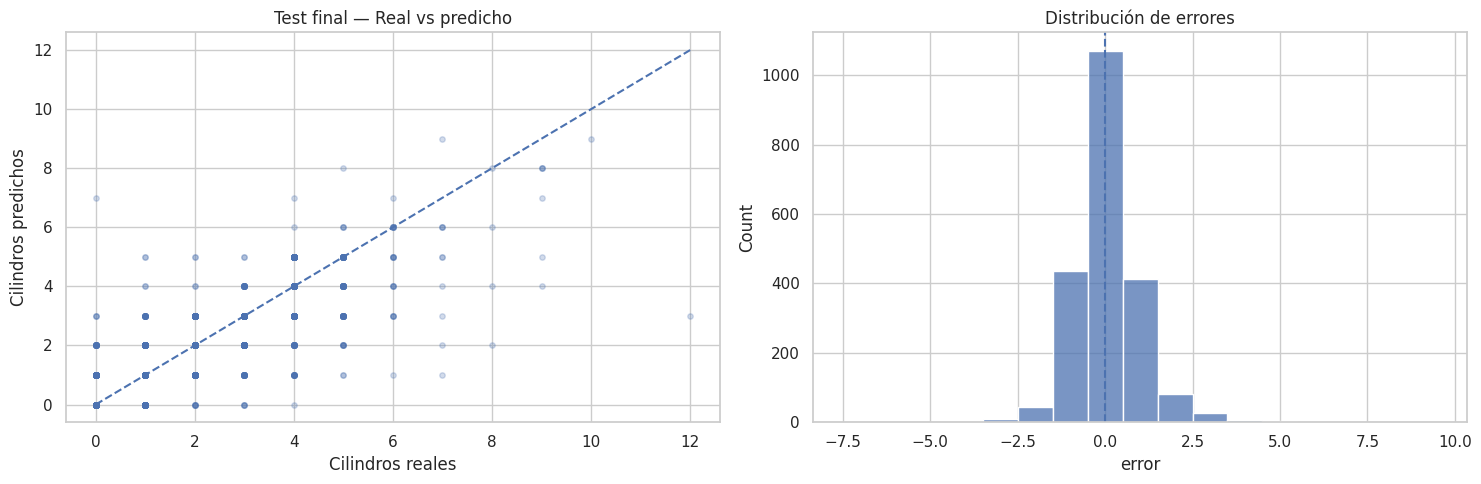

In [ ]:

fig, axes = plt.subplots(1,2,figsize=(15,5))
s = test_results.sample(min(2500,len(test_results)), random_state=RANDOM_STATE)
axes[0].scatter(s['target'], s['pred_cilindros'], alpha=.25, s=15)
mx=max(test_results['target'].max(),test_results['pred_cilindros'].max())
axes[0].plot([0,mx],[0,mx],'--')
axes[0].set_xlabel('Cilindros reales'); axes[0].set_ylabel('Cilindros predichos')
axes[0].set_title('Test final — Real vs predicho')
sns.histplot(test_results['error'], discrete=True, ax=axes[1])
axes[1].axvline(0, linestyle='--')
axes[1].set_title('Distribución de errores')
plt.tight_layout(); plt.show()


## 9. Importancia de variables

,importancia
num__lag_1,0.437922
num__hist_mean,0.327873
num__edad,0.030528
num__hist_median,0.027791
num__lag_2,0.027667
num__hist_min,0.023905
num__hist_std,0.023229
num__hist_nonzero_rate,0.020228
num__hist_sum,0.017316
num__recent_trend,0.011243


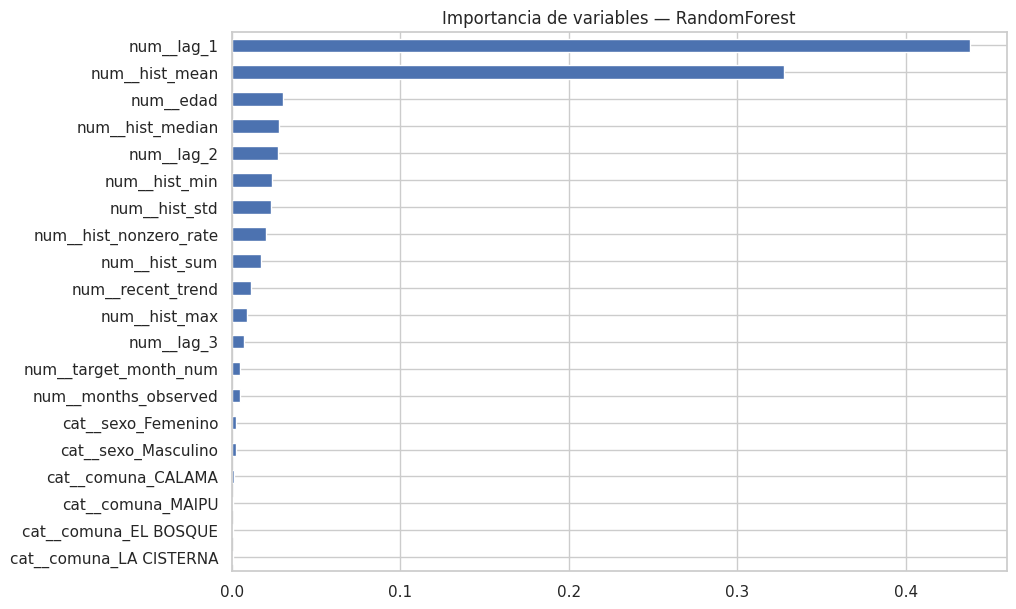

In [ ]:

model_obj = best_pipe.named_steps['model']
if hasattr(model_obj,'feature_importances_'):
    names = best_pipe.named_steps['preprocess'].get_feature_names_out()
    imp = pd.Series(model_obj.feature_importances_, index=names).sort_values(ascending=False)
    display(imp.head(20).to_frame('importancia'))
    plt.figure(figsize=(10,7))
    imp.head(20).sort_values().plot(kind='barh')
    plt.title(f'Importancia de variables — {BEST_MODEL_NAME}')
    plt.show()



## 10. Modelo definitivo y predicción de diciembre

Tras la evaluación, se entrena una nueva instancia con todas las observaciones de abril–noviembre. Luego se usa enero–noviembre de cada paciente para estimar diciembre.


In [ ]:

def build_next_month_features(data, next_month_num=12):
    rows=[]
    for _,row in data.iterrows():
        hist=row[MONTHS].to_numpy(dtype=float)
        last3=hist[-3:]
        rows.append({
            'id':row['id'], 'edad':row['edad'], 'comuna':row['comuna'], 'sexo':row['sexo'],
            'target_month_num':next_month_num,
            'lag_1':hist[-1], 'lag_2':hist[-2], 'lag_3':hist[-3],
            'hist_mean':float(np.mean(hist)), 'hist_median':float(np.median(hist)),
            'hist_std':float(np.std(hist)), 'hist_min':float(np.min(hist)),
            'hist_max':float(np.max(hist)), 'hist_sum':float(np.sum(hist)),
            'hist_nonzero_rate':float(np.mean(hist>0)),
            'recent_trend':recent_trend(last3), 'months_observed':len(hist)
        })
    return pd.DataFrame(rows)

production_pipe = make_pipeline(clone(MODELS[BEST_MODEL_NAME]))
production_pipe.fit(panel[FEATURES], panel['target'])

dec_features = build_next_month_features(df,12)
dec_pred_raw = production_pipe.predict(dec_features[FEATURES])
dec_pred_int = np.clip(np.rint(dec_pred_raw),0,None).astype(int)

predicciones_diciembre = dec_features[['id']].copy()
predicciones_diciembre['prediccion_raw']=dec_pred_raw
predicciones_diciembre['cilindros_estimados']=dec_pred_int

display(predicciones_diciembre.head(20))


,id,prediccion_raw,cilindros_estimados
0,1,0.145458,0
1,2,4.341875,4
2,4,0.607262,1
3,6,0.836058,1
4,8,1.412906,1
5,9,2.560550,3
6,11,2.345622,2
7,12,4.235576,4
8,13,0.409229,0
9,17,3.781611,4


## 11. Función de inferencia por ID

In [ ]:

def predecir_cilindros_proximo_mes(id_paciente, next_month_num=12):
    patient = df[df['id']==id_paciente]
    if patient.empty:
        raise ValueError(f'No existe el ID {id_paciente}.')
    feat = build_next_month_features(patient,next_month_num)
    raw = production_pipe.predict(feat[FEATURES])[0]
    return {
        'id': id_paciente,
        'mes_objetivo': next_month_num,
        'prediccion_raw': round(float(raw),3),
        'cilindros_estimados': int(max(0,round(raw)))
    }

# Ejemplo
predecir_cilindros_proximo_mes(df['id'].iloc[0])


{'id': np.int64(1),
 'mes_objetivo': 12,
 'prediccion_raw': 0.145,
 'cilindros_estimados': 0}

## 12. Guardar modelo y resultados

In [ ]:

MODEL_FILE='modelo_cantidad_cilindros.joblib'
PRED_FILE='predicciones_diciembre.csv'
META_FILE='modelo_cantidad_metadata.json'
TEST_FILE='evaluacion_test_oct_nov.csv'

joblib.dump(production_pipe, MODEL_FILE)
predicciones_diciembre.to_csv(PRED_FILE,index=False)
test_results.to_csv(TEST_FILE,index=False)

metadata={
    'objetivo':'Predecir cantidad de cilindros por paciente para el próximo mes',
    'modelo_seleccionado':BEST_MODEL_NAME,
    'features':FEATURES,
    'id_usado_como_predictor':False,
    'variables_excluidas_por_riesgo_de_leakage':[
        'suma_total','id_num','n_despachos','meses_activos','intervalo_median','cv_intervalo'
    ],
    'test':{
        'meses':['oct','nov'],
        'MAE':float(test_metrics['MAE']),
        'RMSE':float(test_metrics['RMSE']),
        'R2':float(test_metrics['R2']),
        'exactitud':float(test_metrics['Exactitud']),
        'dentro_1_cilindro':float(test_metrics['Dentro_1']),
        'subestima':float(test_metrics['Subestima']),
        'sobreestima':float(test_metrics['Sobreestima'])
    }
}
with open(META_FILE,'w',encoding='utf-8') as f:
    json.dump(metadata,f,indent=2,ensure_ascii=False)

print('Generados:')
for f in [MODEL_FILE,PRED_FILE,META_FILE,TEST_FILE]: print('-',f)


Generados:
- modelo_cantidad_cilindros.joblib
- predicciones_diciembre.csv
- modelo_cantidad_metadata.json
- evaluacion_test_oct_nov.csv


## 13. Descargar artefactos

Se deja como opción descargar el resto de los componentes

In [ ]:

files.download('modelo_cantidad_cilindros.joblib')
# files.download('predicciones_diciembre.csv')
# files.download('modelo_cantidad_metadata.json')
# files.download('evaluacion_test_oct_nov.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# Resultado

El artefacto principal es `modelo_cantidad_cilindros.joblib`. Para integración, la lógica expuesta es:

```python
predecir_cilindros_proximo_mes(id_paciente)
```

Ejemplo conceptual:

```python
{
    "id": 152,
    "mes_objetivo": 12,
    "prediccion_raw": 3.71,
    "cilindros_estimados": 4
}
```

> Este notebook resuelve el componente **CUÁNTO**.
